In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from statsmodels.tsa.stattools import adfuller

import yfinance as yf

tickers = ["V", "MA"]

prices = yf.download(
    tickers,
    start="2016-01-01",
    end="2026-01-01",
    auto_adjust=True,
    progress=False
)["Close"].dropna()

train_prices = prices.loc["2016-01-01":"2021-12-31"].copy()
test_prices = prices.loc["2022-01-01":"2025-12-31"].copy()



In [2]:
log_train = np.log(train_prices)

log_train.head()

Ticker,MA,V
Date,,
2016-01-04,4.486869,4.250725
2016-01-05,4.488766,4.258227
2016-01-06,4.473353,4.245030
2016-01-07,4.454865,4.225171
2016-01-08,4.435584,4.212762


In [3]:
Y = log_train["MA"]
X = log_train["V"]

X_with_constant = sm.add_constant(X)

ols_model = sm.OLS(Y, X_with_constant).fit()

print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:                     MA   R-squared:                       0.996
Model:                            OLS   Adj. R-squared:                  0.996
Method:                 Least Squares   F-statistic:                 3.547e+05
Date:                Thu, 03 Sep 2026   Prob (F-statistic):               0.00
Time:                        19:42:05   Log-Likelihood:                 3058.0
No. Observations:                1511   AIC:                            -6112.
Df Residuals:                    1509   BIC:                            -6101.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.8693      0.010    -84.254      0.0

In [4]:
alpha = ols_model.params["const"]
beta = ols_model.params["V"]

print(f"Alpha: {alpha:.4f}")
print(f"Beta:  {beta:.4f}")

Alpha: -0.8693
Beta:  1.2559


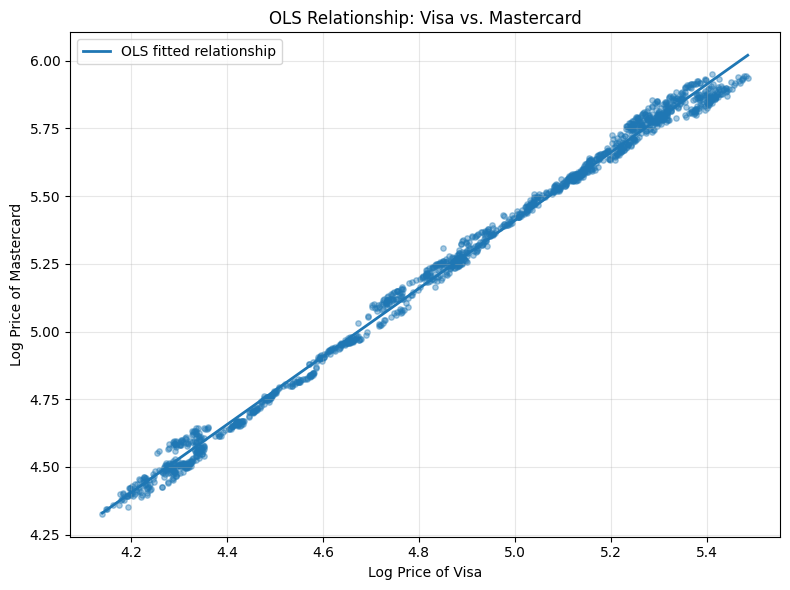

In [5]:
plt.figure(figsize=(8, 6))

plt.scatter(
    log_train["V"],
    log_train["MA"],
    alpha=0.4,
    s=15
)

x_line = np.linspace(
    log_train["V"].min(),
    log_train["V"].max(),
    200
)

y_line = alpha + beta * x_line

plt.plot(
    x_line,
    y_line,
    linewidth=2,
    label="OLS fitted relationship"
)

plt.title("OLS Relationship: Visa vs. Mastercard")
plt.xlabel("Log Price of Visa")
plt.ylabel("Log Price of Mastercard")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [6]:
predicted_ma = alpha + beta * log_train["V"]

predicted_ma.head()

Date
2016-01-04    4.469084
2016-01-05    4.478505
2016-01-06    4.461931
2016-01-07    4.436990
2016-01-08    4.421406
Name: V, dtype: float64

In [7]:
spread = (
    log_train["MA"]
    - (alpha + beta * log_train["V"])
)

spread.head()

Date
2016-01-04    0.017785
2016-01-05    0.010261
2016-01-06    0.011422
2016-01-07    0.017875
2016-01-08    0.014177
dtype: float64

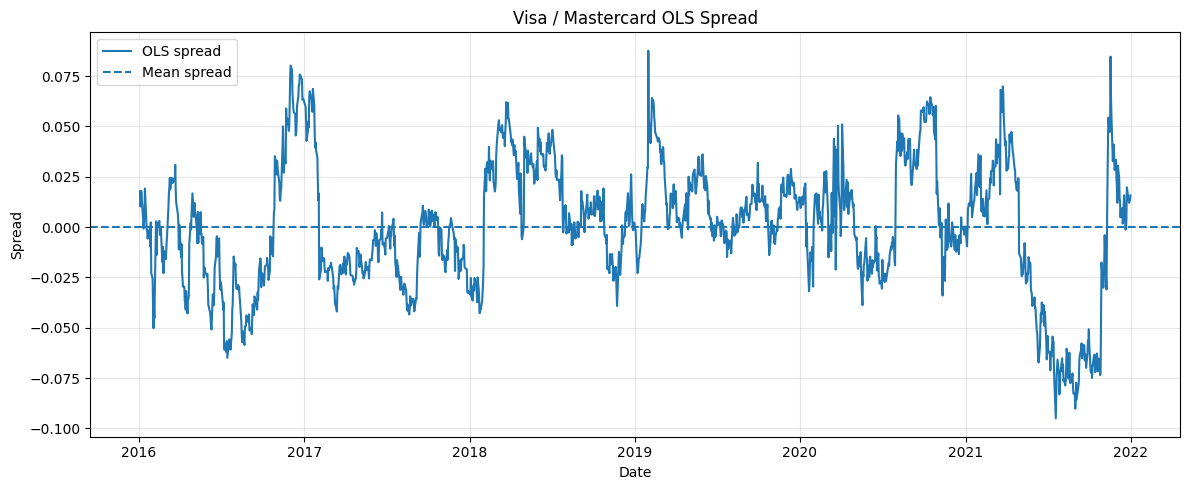

In [8]:
spread_mean = spread.mean()

plt.figure(figsize=(12, 5))

plt.plot(
    spread.index,
    spread,
    label="OLS spread"
)

plt.axhline(
    spread_mean,
    linestyle="--",
    label="Mean spread"
)

plt.title("Visa / Mastercard OLS Spread")
plt.xlabel("Date")
plt.ylabel("Spread")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

AUGMENTED DICKEY FULLER TEST

In [9]:
adf_result = adfuller(spread)

adf_statistic = adf_result[0]
adf_pvalue = adf_result[1]

print(f"ADF Statistic: {adf_statistic:.4f}")
print(f"p-value:       {adf_pvalue:.4f}")

ADF Statistic: -4.2349
p-value:       0.0006


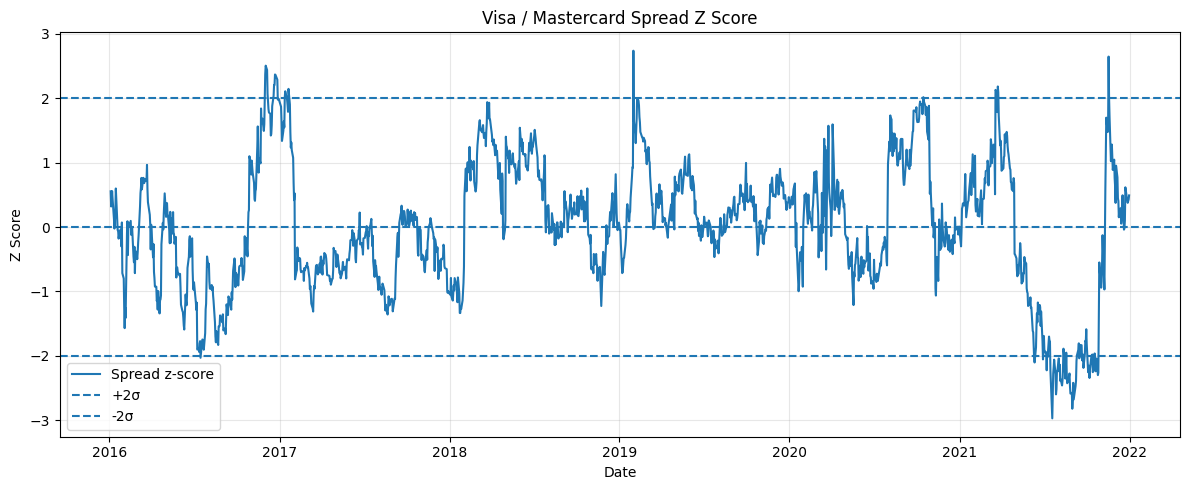

In [12]:
spread_std = spread.std()

z_score = (
    spread - spread_mean
) / spread_std

plt.figure(figsize=(12, 5))

plt.plot(
    z_score.index,
    z_score,
    label="Spread z-score"
)

plt.axhline(0, linestyle="--")
plt.axhline(2, linestyle="--", label="+2σ")
plt.axhline(-2, linestyle="--", label="-2σ")

plt.title("Visa / Mastercard Spread Z Score")
plt.xlabel("Date")
plt.ylabel("Z Score")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()